# FinSight AI - Notebook 1: Financial Data Preparation

**Objective:** Build the clean financial corpus that will be used for Domain-Adaptive Continued Pretraining (DAPT) in Notebook 2.

Pipeline:

`Financial PDFs → PDF extraction → cleaning → metadata → EDA → document-level split → JSONL corpus`

**Important:** Evaluation datasets are intentionally not loaded or used in this notebook.

## 1. Install Dependencies

Run this cell once in Google Colab.

In [3]:
!pip -q install pymupdf pandas numpy matplotlib seaborn tqdm

## 2. Imports and Configuration

In [7]:
from pathlib import Path
import json
import re
import unicodedata

import fitz  # PyMuPDF
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

SEED = 42
np.random.seed(SEED)

# Change this path after uploading the corpus to Colab.
TRAINING_DATA_DIR = Path('/content/Dataset_Domain_Specific_Traning')

OUTPUT_DIR = Path('/content/Domain_Specific_Traning_processed_data')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f'Training directory: {TRAINING_DATA_DIR}')
print(f'Output directory: {OUTPUT_DIR}')

Training directory: /content/Dataset_Domain_Specific_Traning
Output directory: /content/Domain_Specific_Traning_processed_data


## 3. Upload / Locate the 12 Training PDFs

Upload **only the 12 training PDFs** here. Do not upload the evaluation package into this directory.

In [8]:
# If using Colab, uncomment the next two lines to upload the ZIP containing the 12 training PDFs.
# from google.colab import files
# uploaded = files.upload()

pdf_files = sorted(TRAINING_DATA_DIR.glob('*.pdf'))

print(f'Found {len(pdf_files)} PDF files.')
for pdf in pdf_files:
    print(pdf.name)

Found 12 PDF files.
finorapay_technologies_inc_annual_report_2025.pdf
finorapay_technologies_inc_earnings_call_q2_2026.pdf
finorapay_technologies_inc_investor_presentation_q2_2026.pdf
finorapay_technologies_inc_quarterly_report_q2_2026.pdf
meridian_crest_bank_holdings_inc_annual_report_2025.pdf
meridian_crest_bank_holdings_inc_earnings_call_q2_2026.pdf
meridian_crest_bank_holdings_inc_investor_presentation_q2_2026.pdf
meridian_crest_bank_holdings_inc_quarterly_report_q2_2026.pdf
summit_arc_asset_management_plc_annual_report_2025.pdf
summit_arc_asset_management_plc_earnings_call_q2_2026.pdf
summit_arc_asset_management_plc_investor_presentation_q2_2026.pdf
summit_arc_asset_management_plc_quarterly_report_q2_2026.pdf


In [9]:
assert len(pdf_files) == 12, (
    f'Expected 12 training PDFs, but found {len(pdf_files)}. '
    'Check that only the 12 training documents are in the directory.'
)

## 4. Extract Text and Basic PDF Metadata

We preserve page-level information because it will be useful later for traceability and document-level analysis.

In [10]:
def extract_pdf(pdf_path: Path) -> dict:
    """Extract page-level text and basic metadata from a PDF."""
    doc = fitz.open(pdf_path)

    pages = []
    total_chars = 0

    for page_number, page in enumerate(doc, start=1):
        text = page.get_text('text') or ''
        total_chars += len(text)
        pages.append({
            'page_number': page_number,
            'text': text,
            'char_count': len(text),
        })

    metadata = doc.metadata or {}
    result = {
        'filename': pdf_path.name,
        'page_count': len(doc),
        'total_characters': total_chars,
        'pdf_metadata': metadata,
        'pages': pages,
    }
    doc.close()
    return result


documents = [extract_pdf(path) for path in tqdm(pdf_files, desc='Extracting PDFs')]

print(f'Extracted {len(documents)} documents.')

Extracting PDFs:   0%|          | 0/12 [00:00<?, ?it/s]

Extracted 12 documents.


## 5. Build Document-Level Metadata

Our filenames encode the fictional company and document type. We use that information for analysis and, importantly, for leakage-safe splitting.

In [11]:
def infer_metadata(filename: str) -> dict:
    name = filename.lower().replace('.pdf', '')

    if 'annual_report' in name:
        document_type = 'annual_report'
    elif 'quarterly_report' in name:
        document_type = 'quarterly_report'
    elif 'earnings_call' in name:
        document_type = 'earnings_call'
    elif 'investor_presentation' in name:
        document_type = 'investor_presentation'
    else:
        document_type = 'unknown'

    company = name
    company = re.sub(r'_(annual_report|quarterly_report|earnings_call|investor_presentation).*$', '', company)
    company = company.replace('_', ' ').title()

    return {
        'company': company,
        'document_type': document_type,
    }


for document in documents:
    document.update(infer_metadata(document['filename']))

metadata_df = pd.DataFrame([
    {
        'filename': d['filename'],
        'company': d['company'],
        'document_type': d['document_type'],
        'page_count': d['page_count'],
        'total_characters': d['total_characters'],
    }
    for d in documents
])

metadata_df

,filename,company,document_type,page_count,total_characters
0,finorapay_technologies_inc_annual_report_2025.pdf,Finorapay Technologies Inc,annual_report,4,5589
1,finorapay_technologies_inc_earnings_call_q2_20...,Finorapay Technologies Inc,earnings_call,2,2875
2,finorapay_technologies_inc_investor_presentati...,Finorapay Technologies Inc,investor_presentation,3,3609
3,finorapay_technologies_inc_quarterly_report_q2...,Finorapay Technologies Inc,quarterly_report,3,2869
4,meridian_crest_bank_holdings_inc_annual_report...,Meridian Crest Bank Holdings Inc,annual_report,4,5591
5,meridian_crest_bank_holdings_inc_earnings_call...,Meridian Crest Bank Holdings Inc,earnings_call,2,3126
6,meridian_crest_bank_holdings_inc_investor_pres...,Meridian Crest Bank Holdings Inc,investor_presentation,3,3612
7,meridian_crest_bank_holdings_inc_quarterly_rep...,Meridian Crest Bank Holdings Inc,quarterly_report,3,2942
8,summit_arc_asset_management_plc_annual_report_...,Summit Arc Asset Management Plc,annual_report,4,5649
9,summit_arc_asset_management_plc_earnings_call_...,Summit Arc Asset Management Plc,earnings_call,2,2833


## 6. Text Cleaning

The goal is **light cleaning**, not aggressive preprocessing. We want to preserve financial terminology, numbers, percentages, currencies, and document structure.

In [12]:
def clean_text(text: str) -> str:
    """Lightly normalize extracted PDF text while preserving financial content."""
    text = unicodedata.normalize('NFKC', text)

    # Normalize line endings and whitespace.
    text = text.replace('\r\n', '\n').replace('\r', '\n')
    text = re.sub(r'[ \t]+', ' ', text)

    # Remove spaces around line breaks and collapse excessive blank lines.
    text = re.sub(r' *\n *', '\n', text)
    text = re.sub(r'\n{3,}', '\n\n', text)

    return text.strip()


for document in documents:
    for page in document['pages']:
        page['clean_text'] = clean_text(page['text'])

    document['clean_text'] = '\n\n'.join(
        page['clean_text'] for page in document['pages'] if page['clean_text']
    )
    document['clean_characters'] = len(document['clean_text'])

metadata_df = pd.DataFrame([
    {
        'filename': d['filename'],
        'company': d['company'],
        'document_type': d['document_type'],
        'pages': d['page_count'],
        'raw_chars': d['total_characters'],
        'clean_chars': d['clean_characters'],
    }
    for d in documents
])

metadata_df

,filename,company,document_type,pages,raw_chars,clean_chars
0,finorapay_technologies_inc_annual_report_2025.pdf,Finorapay Technologies Inc,annual_report,4,5589,5591
1,finorapay_technologies_inc_earnings_call_q2_20...,Finorapay Technologies Inc,earnings_call,2,2875,2875
2,finorapay_technologies_inc_investor_presentati...,Finorapay Technologies Inc,investor_presentation,3,3609,3610
3,finorapay_technologies_inc_quarterly_report_q2...,Finorapay Technologies Inc,quarterly_report,3,2869,2870
4,meridian_crest_bank_holdings_inc_annual_report...,Meridian Crest Bank Holdings Inc,annual_report,4,5591,5593
5,meridian_crest_bank_holdings_inc_earnings_call...,Meridian Crest Bank Holdings Inc,earnings_call,2,3126,3126
6,meridian_crest_bank_holdings_inc_investor_pres...,Meridian Crest Bank Holdings Inc,investor_presentation,3,3612,3613
7,meridian_crest_bank_holdings_inc_quarterly_rep...,Meridian Crest Bank Holdings Inc,quarterly_report,3,2942,2943
8,summit_arc_asset_management_plc_annual_report_...,Summit Arc Asset Management Plc,annual_report,4,5649,5651
9,summit_arc_asset_management_plc_earnings_call_...,Summit Arc Asset Management Plc,earnings_call,2,2833,2833


## 7. EDA: Corpus Overview

In [13]:
print('Documents:', len(metadata_df))
print('Companies:', metadata_df['company'].nunique())
print('Document types:', metadata_df['document_type'].nunique())
print('Total pages:', metadata_df['pages'].sum())
print('Total cleaned characters:', metadata_df['clean_chars'].sum())

metadata_df.groupby('company').agg(
    documents=('filename', 'count'),
    pages=('pages', 'sum'),
    characters=('clean_chars', 'sum')
).sort_values('characters', ascending=False)

Documents: 12
Companies: 3
Document types: 4
Total pages: 36
Total cleaned characters: 45225


,documents,pages,characters
company,,,
Meridian Crest Bank Holdings Inc,4,12,15275
Summit Arc Asset Management Plc,4,12,15004
Finorapay Technologies Inc,4,12,14946


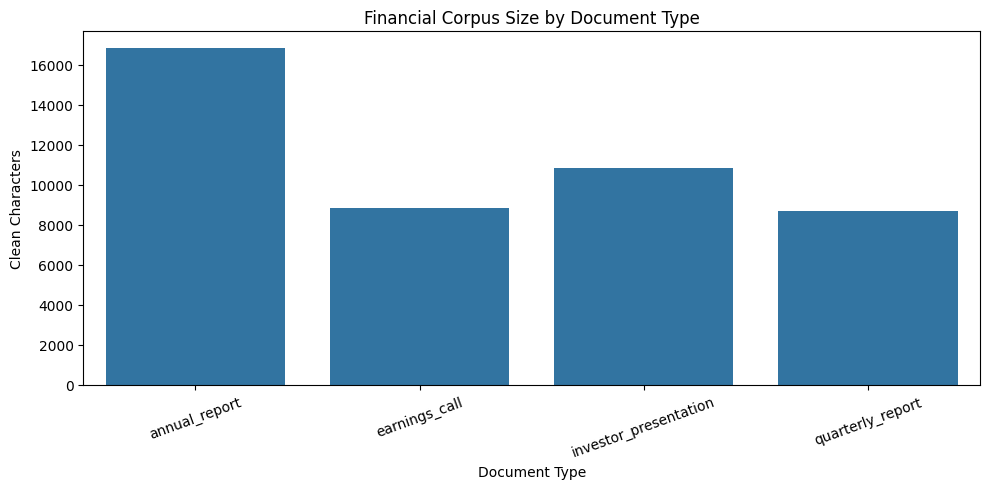

In [14]:
plt.figure(figsize=(10, 5))
sns.barplot(data=metadata_df, x='document_type', y='clean_chars', estimator=sum, errorbar=None)
plt.title('Financial Corpus Size by Document Type')
plt.xlabel('Document Type')
plt.ylabel('Clean Characters')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

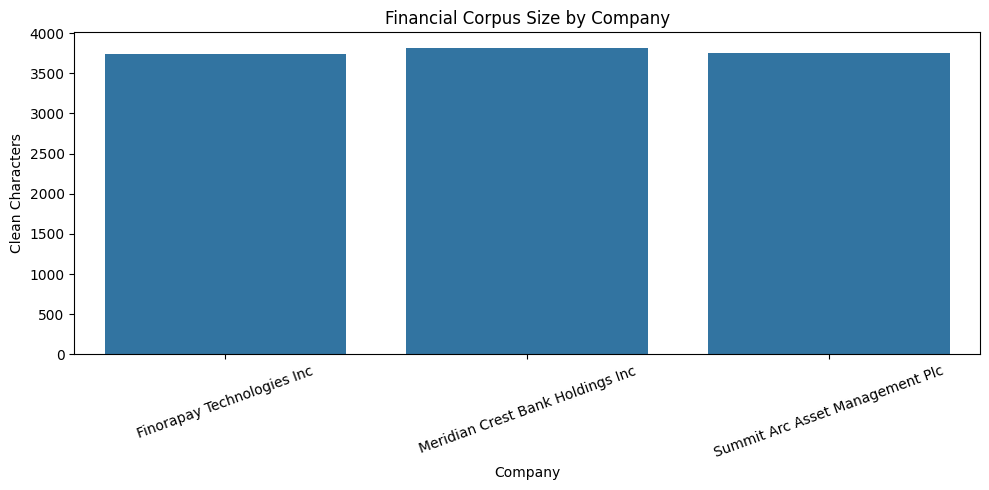

In [15]:
plt.figure(figsize=(10, 5))
sns.barplot(data=metadata_df, x='company', y='clean_chars', errorbar=None)
plt.title('Financial Corpus Size by Company')
plt.xlabel('Company')
plt.ylabel('Clean Characters')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## 8. Basic Financial-Language Analysis

This is intentionally lightweight EDA. We want to understand the corpus before training rather than build a full NLP analytics system.

In [16]:
FINANCIAL_TERMS = [
    'revenue', 'operating income', 'net income', 'cash flow', 'debt',
    'ebitda', 'margin', 'risk', 'guidance', 'capital expenditure',
    'assets', 'liabilities', 'equity', 'earnings', 'growth'
]

def term_counts(text: str) -> dict:
    lower = text.lower()
    return {term: len(re.findall(r'\b' + re.escape(term) + r'\b', lower)) for term in FINANCIAL_TERMS}


term_df = pd.DataFrame([term_counts(d['clean_text']) for d in documents])
term_df.index = metadata_df['filename']
term_totals = term_df.sum().sort_values(ascending=False)
term_totals.head(15)

,0
revenue,75
risk,55
growth,39
assets,24
net income,23
margin,22
earnings,13
equity,6
guidance,4
cash flow,4


## 9. Create Document-Level Training Records

For DAPT, the model learns from continuous financial text. We therefore keep the document identity and metadata attached to each record.

In [17]:
records = []

for document in documents:
    records.append({
        'document_id': Path(document['filename']).stem,
        'filename': document['filename'],
        'company': document['company'],
        'document_type': document['document_type'],
        'text': document['clean_text'],
    })

corpus_df = pd.DataFrame(records)
corpus_df[['document_id', 'company', 'document_type', 'text']].head(2)

,document_id,company,document_type,text
0,finorapay_technologies_inc_annual_report_2025,Finorapay Technologies Inc,annual_report,Synthetic training document - FinSight AI Fina...
1,finorapay_technologies_inc_earnings_call_q2_2026,Finorapay Technologies Inc,earnings_call,Synthetic training document - FinSight AI Fina...


## 10. Leakage-Safe Train / Validation Split

We split at the **document level**, never at random text chunks. This prevents pages from the same report appearing in both training and validation.

For this small synthetic corpus, use approximately 10 documents for training and 2 for validation. The independent benchmark/custom test set remains completely separate.

In [18]:
shuffled = corpus_df.sample(frac=1, random_state=SEED).reset_index(drop=True)
n_val = max(2, round(len(shuffled) * 0.17))

val_df = shuffled.iloc[:n_val].copy()
train_df = shuffled.iloc[n_val:].copy()

print(f'Train documents: {len(train_df)}')
print(f'Validation documents: {len(val_df)}')

print('\nTrain companies:')
print(sorted(train_df['company'].unique()))

print('\nValidation documents:')
print(val_df[['filename', 'company', 'document_type']].to_string(index=False))

Train documents: 10
Validation documents: 2

Train companies:
['Finorapay Technologies Inc', 'Meridian Crest Bank Holdings Inc', 'Summit Arc Asset Management Plc']

Validation documents:
                                                         filename                         company         document_type
summit_arc_asset_management_plc_investor_presentation_q2_2026.pdf Summit Arc Asset Management Plc investor_presentation
        summit_arc_asset_management_plc_earnings_call_q2_2026.pdf Summit Arc Asset Management Plc         earnings_call


## 11. Create DAPT JSONL Files

These files will be consumed by Notebook 2. We store only the clean text and metadata needed for continued pretraining.

In [19]:
train_path = OUTPUT_DIR / 'dapt_train.jsonl'
val_path = OUTPUT_DIR / 'dapt_validation.jsonl'
metadata_path = OUTPUT_DIR / 'corpus_metadata.csv'

def write_jsonl(df: pd.DataFrame, path: Path) -> None:
    with path.open('w', encoding='utf-8') as f:
        for row in df.to_dict(orient='records'):
            f.write(json.dumps(row, ensure_ascii=False) + '\n')


write_jsonl(train_df, train_path)
write_jsonl(val_df, val_path)
metadata_df.to_csv(metadata_path, index=False)

print(f'Saved: {train_path}')
print(f'Saved: {val_path}')
print(f'Saved: {metadata_path}')

Saved: /content/Domain_Specific_Traning_processed_data/dapt_train.jsonl
Saved: /content/Domain_Specific_Traning_processed_data/dapt_validation.jsonl
Saved: /content/Domain_Specific_Traning_processed_data/corpus_metadata.csv


## 12. Final Data Quality Checks

In [20]:
assert train_df['text'].str.len().min() > 0
assert val_df['text'].str.len().min() > 0
assert set(train_df['document_id']).isdisjoint(set(val_df['document_id']))
assert len(train_df) + len(val_df) == len(corpus_df)

print('✓ No empty training documents')
print('✓ No empty validation documents')
print('✓ No document overlap between train and validation')
print('✓ All documents accounted for')

print('\nNotebook 1 complete.')

✓ No empty training documents
✓ No empty validation documents
✓ No document overlap between train and validation
✓ All documents accounted for

Notebook 1 complete.


## Outputs from Notebook 1

The important outputs are:

- `dapt_train.jsonl`
- `dapt_validation.jsonl`
- `corpus_metadata.csv`

Next: **Notebook 2 - Domain-Adaptive Continued Pretraining with LoRA/QLoRA.**